# Pacbio processing

Use long read data to make barcode-substitution map used by 10x

Each pacbio read should cover the STING coding region, followed by a downstream region that contains:
- 21 bp fixed sequence
- 16 bp barcode - unique clonal identifier
- 4 bp spacer - usually CGCT but sometimes XXXX
- 16 digit TWIST barcode - indicates the position of the AA mutation in STING
- 1-bp spacer
- 22 bp 10x capture sequence (fixed)

This code reads through the reads, aligns to STING sequence, and matches the observed AA mutations in STING with the 16+4+16 bp barcode
to create a barcode-variant map, which is later used to assign variants in 10x cells


The github repository contains example data which runs very fast. Runtime on actual pacbio hifi files takes a few hours.

In [1]:
import csv
import multiprocessing
import os
import subprocess
import sys
import time
from importlib.metadata import version
from io import StringIO

import editdistance  # pip install editdistance
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from cigar import Cigar  # pip install Cigar
from matplotlib.colors import ListedColormap
from matplotlib.patches import Rectangle


In [2]:
print(f"Python: {sys.version.split()[0]}")

packages = [
    "editdistance",
    "matplotlib",
    "numpy",
    "pandas",
    "seaborn",
    "Cigar",
]

for package in packages:
    print(f"{package}: {version(package)}")

Python: 3.10.12
editdistance: 0.8.1
matplotlib: 3.8.3
numpy: 1.26.4
pandas: 2.2.1
seaborn: 0.13.2
Cigar: 0.1.3


__Minimap2 is needed, set path to minimap2 or else use next cell to download it__

In [3]:
minimap2_executable='/opt/minimap2-2.28_x64-linux/minimap2'

In [4]:
# Get minimap2 if needed
if minimap2_executable is None or not os.path.exists(minimap2_executable):
    !mkdir -p /opt
    !cd /opt && wget https://github.com/lh3/minimap2/releases/download/v2.28/minimap2-2.28_x64-linux.tar.bz2  && tar -jxvf minimap2-2.28_x64-linux.tar.bz2
    minimap2_executable='/opt/minimap2-2.28_x64-linux/minimap2'

In [5]:
!{minimap2_executable} --version

2.28-r1209


## Initial set-up

In [6]:
# set this to SatSeq_10x_Variant_Calling dir from github repository

basedir='/data/satseq_processing/SatSeq_10x_Variant_Calling'
os.chdir(basedir)

__Set input file name (.bam from pacbio)__

In [7]:
# bamfile - this is small example
bamfile='data/examples/pacbio_example_reads.bam'

# Real data deposited into NCBI SRA PRJNA1552726:

#bamfile='m84094_240603_153822_s1.hifi_reads.bam'   ## EO771.lmb library 1
#bamfile='m84094_240603_173728_s2.hifi_reads.bam'   ## EO771.lmb library 2
#bamfile='m84094_241218_161022_s4.hifi_reads.bam'   ## 4T1 library 1
#bamfile='m84094_250121_165133_s1.hifi_reads.bam'   ## 4T1 library 2
#bamfile='m84094_240928_172919_s3.hifi_reads.bam'   ## plasmid unamplified library 
#bamfile='m84094_250121_205730_s3.hifi_reads.bam'   ## plasmid amplified library 


In [8]:
if not os.path.exists(bamfile):
    print(f'{bamfile} not found')
elif not os.path.exists(f'{bamfile}.bai'):
    print(f'Indexing bamfile...')
    !samtools index {bamfile}
    print(f'Done.')

Indexing bamfile...
[E::sam_index_build3] SAM file "data/examples/pacbio_example_reads.bam" not BGZF compressed
samtools index: failed to create index for "data/examples/pacbio_example_reads.bam"
Done.


In [9]:
refseq_file='data/STING.fa'

__Set output directory__

In [10]:
# set directory for output files / plots
output_dir='output/01_output'
!mkdir -p {output_dir}

__Set sample name__

In [11]:
# set name of the sample to appear in plot titles
sample_name='EO771.lmb pacbio run 1 example reads'

# Replace spaces with underscore for ouptut filenames
sample_name_nospace=sample_name.replace(' ', '_')  

__Set 10x barcode__

In [12]:
# Set 10x barcode / capture sequence
bc10x='GCTTTAAGGCCGGTCCTAGCAA'

__Read in reference STING sequence and get coding start/end positions info__

In this notebook, there is only one reference sequence. But there could be multiple reference sequences in the fasta file, in which case it would align
long reads against all of them. This was originally intended to support some special STING variants (dUPR/dCTT) that have different lengths than WT sting,
but we found it was not necessary, the mapping worked OK for all variants using one single reference

In [13]:
with open(refseq_file, 'r') as f:
    tmpseq = f.readlines()
    f.close()
    refgene = {}
    for line in tmpseq:
        if line.startswith('>'):
            seqname = line[1:].strip()
            print(seqname)
            refgene[seqname]=''
        else:
            refgene[seqname] = refgene[seqname]+line.strip()
    print(refgene.keys())

STING
dict_keys(['STING'])


In [14]:
codon_table = {
    # 'M' - START, '_' - STOP
    "GCT": "A", "GCC": "A", "GCA": "A", "GCG": "A",
    "TGT": "C", "TGC": "C",
    "GAT": "D", "GAC": "D",
    "GAA": "E", "GAG": "E",
    "TTT": "F", "TTC": "F",
    "GGT": "G", "GGC": "G", "GGA": "G", "GGG": "G",
    "CAT": "H", "CAC": "H",
    "ATA": "I", "ATT": "I", "ATC": "I",
    "AAA": "K", "AAG": "K",
    "TTA": "L", "TTG": "L", "CTT": "L", "CTC": "L", "CTA": "L", "CTG": "L",
    "ATG": "M",
    "AAT": "N", "AAC": "N",
    "CCT": "P", "CCC": "P", "CCA": "P", "CCG": "P",
    "CAA": "Q", "CAG": "Q",
    "CGT": "R", "CGC": "R", "CGA": "R", "CGG": "R", "AGA": "R", "AGG": "R",
    "TCT": "S", "TCC": "S", "TCA": "S", "TCG": "S", "AGT": "S", "AGC": "S",
    "ACT": "T", "ACC": "T", "ACA": "T", "ACG": "T",
    "GTT": "V", "GTC": "V", "GTA": "V", "GTG": "V",
    "TGG": "W",
    "TAT": "Y", "TAC": "Y",
    "TAA": "_", "TAG": "_", "TGA": "_"
}


In [15]:
# find start position of STING in the reference sequence, and the end codon
genestart = {}
geneend = {}
refgene_aa = {}
for k,refseq in refgene.items():
    genestart[k] = refseq.find('ATGCCATACTCCAACCTGCATCCAGCCATCCCAC')
    aaseq=''
    for i in np.arange(genestart[k], len(refseq), 3):
        aa = codon_table[refseq[i:(i+3)]]
        aaseq += aa
        if aa == '_':
            geneend[k] = i
            break
    print(k, len(aaseq))
    refgene_aa[k] = aaseq

STING 379


In [16]:
genestart

{'STING': 465}

In [17]:
geneend

{'STING': 1599}

__Read in twist variants__

In [18]:
variants = pd.read_csv('data/twist_mSTING_full_feature_ref_v3.csv', index_col=0)
variants = variants.set_index('name', drop=True)

In [19]:
# This dataframe should have variant as the index, and the associated barcode as the 'sequence'. Other columns are not used here
variants

,read,pattern,sequence,feature_type
name,,,,
mSTING_WT,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CGAGGAATTAGCAACG,Custom
STOP,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GTAATGAATACCGAGG,Custom
V146L,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGGCGGCGAATATAGC,Custom
N153S,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),CCTCGAGAACTTTCCT,Custom
V154M,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GGAATCAGACTGAAAC,Custom
...,...,...,...,...
R374X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GCTAACCAACTACCTC,Custom
T375X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),TGTAACATCCGTCGAA,Custom
D376X,R2,^AAGAACCTTGCGGGTAAATCNNNNNNNNNNNNNNNNNNNN(BC),GAGTTACTCATCGTCT,Custom


In [20]:
len('ATCNNNNNNNNNNNNNNNNNNNN')

23

In [21]:
# check the barcode len, should be same for all sequences
{len(x) for x in variants['sequence']}

{16}

In [22]:
# assign a position, wt AA, and mutant AA to each variant. Most are indicated in variant name,
# but some special ones need values assigned. Use negative positions for non-positional variants

variants['pos'] = -1
variants['wt_aa'] = ''
variants['mut_aa'] = ''
for x in variants.index:
    wtaa=''
    mutaa=''
    pos=-100
    if x == 'STOP':
        pos = -2
    elif x == 'mSTING_WT':
        pos = 0
    elif x == 'dUPR':
        pos = -1
    elif x == 'dCTT':
        pos = -3
    elif x == 'RRDD':
        pos = -4
    elif x == 'RRAA':
        pos = -5
    elif x == '261X':
        pos = 261
        tmp = genestart['STING'] + 260*3
        wtaa=codon_table[refgene['STING'][tmp:(tmp+3)]]
        
    else:
        if x[len(x)-1] == 'X' or x=='V146L' or x == 'N153S' or x=='Y239S' or x == 'S365A' or x == 'V154M' or x=='S161A' or x=='I229A' or x=='N241A':
            tmp = int(x[1:(len(x)-1)])
            pos = tmp
            wtaa=x[0]
            mutaa=x[len(x)-1]
        else:
            print(f'Error {x}')
    variants.loc[x,'pos'] = pos
    variants.loc[x,'wt_aa'] = wtaa
    variants.loc[x,'mut_aa'] = mutaa

## preprocessing: convert input files to fastq.gz and do alignment with minimap

These steps may take up to an hour (esp alignment step)

In [23]:
# Use minimap2 to align long reads to each version of refseq
for ref in ['STING']:
    aligned_file =f'{output_dir}/{ref}.bam'
    cmd=f'samtools bam2fq {bamfile} | {minimap2_executable} --eqx -ax map-hifi -t 10 {refseq_file} - | samtools view -b -o {aligned_file}'
    print(f'Calling: {cmd}')
    !{cmd}
print('Done')

Calling: samtools bam2fq data/examples/pacbio_example_reads.bam | /opt/minimap2-2.28_x64-linux/minimap2 --eqx -ax map-hifi -t 10 data/STING.fa - | samtools view -b -o output/01_output/STING.bam
[M::mm_idx_gen::0.002*2.71] collected minimizers
[M::mm_idx_gen::0.004*5.69] sorted minimizers
[M::main::0.004*5.64] loaded/built the index for 1 target sequence(s)
[M::mm_mapopt_update::0.004*5.45] mid_occ = 50
[M::mm_idx_stat] kmer size: 19; skip: 19; is_hpc: 0; #seq: 1
[M::mm_idx_stat::0.004*5.30] distinct minimizers: 166 (100.00% are singletons); average occurrences: 1.000; average spacing: 10.777; total length: 1789
[M::bam2fq_mainloop] discarded 0 singletons
[M::bam2fq_mainloop] processed 2109 reads
[M::worker_pipeline::0.230*4.10] mapped 2109 sequences
[M::main] Version: 2.28-r1209
[M::main] CMD: /opt/minimap2-2.28_x64-linux/minimap2 --eqx -ax map-hifi -t 10 data/STING.fa -
[M::main] Real time: 0.231 sec; CPU: 0.944 sec; Peak RSS: 0.025 GB
Done


## Parse alignment to get AA mutations and barcodes

In [24]:
def get_aa_from_codon(cod):
    if '-' in cod:
        return '-'
    if cod in codon_table:
        return codon_table[cod]
    return '?'


    

# Here is main code for processing each line from alignment output.
# The input is a single line from output sam file
# The output is either a string containing an error message, or a dictionary containing information about the alignment,
#   the number/identity of AA mutations in the read, the barcode and position, etc
def process_alignment_line(nextitr):
    (lineNo,fields) = nextitr
    if fields[3] == '0':
        return 'not_aligned'
    flag = int(fields[1])
    if flag >= 256:
        flag = flag - 256
    if flag >= 32:
        #print(f'Error flag={flag}')
        return 'investigate flag'
    if flag >= 16:
        flag = flag - 16
    if flag >= 8:
        return 'investigate flag2'
    if flag !=0:
        return 'skipped'
    if int(fields[4]) != 60:  # only a  handful do not have quality=60
        return 'lowqual'
    rgene = fields[2]
    seq = fields[9]    
    startpos = int(fields[3])-1
    if startpos > genestart[rgene]:
        return 'no gene seq'
        #return f' {lineNo} {fields[0]} no gene seq'        
    newseq = refgene[rgene][:startpos]
    currpos=0
    cigar_score=0
    cigarstr = fields[5]
    #reflen=0
    reflen=startpos
    numdel=0
    numins=0
    inspos=[]
    delpos=[]
    geneEndPos=-1
    for c in Cigar(cigarstr).items():
        cigarlen = c[0]
        if c[1] == '=' or c[1] == 'X':
            newseq = newseq + seq[currpos:(currpos+cigarlen)]
            reflen += cigarlen
            if c[1] == 'X':
                cigar_score += cigarlen
        elif c[1] == 'D':
            reflen += cigarlen
            newseq = newseq + '-'*cigarlen
            cigar_score += cigarlen
            if (len(newseq) > genestart[rgene]) and (len(newseq) < geneend[rgene]):
                numdel += cigarlen
                delpos.append(f'{len(newseq) - genestart[rgene]}:{cigarlen}')
                    #return f'{lineNo} {rgene} deletion {pos10x-currpos} {cigarlen} {cigarstr}'
        elif c[1] == 'I' or c[1] == 'S':
            if c[1] == 'I':
                cigar_score += cigarlen
                if (len(newseq) > genestart[rgene]) and (len(newseq) < geneend[rgene]):
                    numins += cigarlen
                    inspos.append(f'{len(newseq) - genestart[rgene]}:{cigarlen}')
                    #return f'{lineNo} {rgene} insertion {pos10x-currpos} {cigarlen} {cigarstr}'
        else:
            return f'cigarErr {cigarstr}'
        if geneEndPos == -1 and len(newseq) > geneend[rgene]:
            if c[1] == 'D':
                geneEndPos = currpos
            else:
                geneEndPos = currpos + cigarlen - (len(newseq) - geneend[rgene])
        if c[1] != 'D':
            currpos = currpos + cigarlen
            
    if reflen < len(refgene[rgene])-10:
        return f'not enough {rgene} coverage'

    pos10x = seq[geneEndPos:].find(bc10x)
    if pos10x == -1:
        return('no 10x')
    pos10x0 = pos10x + geneEndPos
    bc = seq[(pos10x0-37):(pos10x0-1)]
    newgene = newseq
    numcodon=0
    aasub=[]
    codsub=[]
    numaa=0
    pos = 0
    for i in np.arange(genestart[rgene], genestart[rgene]+3*len(refgene_aa[rgene]), 3):
        if newgene[i:(i+3)] != refgene[rgene][i:(i+3)]:
            numcodon=numcodon+1
            aa_orig = refgene_aa[rgene][pos]
            new_aa = get_aa_from_codon(newgene[i:(i+3)])
            if new_aa == '-':
                #numdel=numdel+1
                pos=pos+1
                continue
            currcodon=refgene[rgene][i:(i+3)] + str(pos+1) + newgene[i:(i+3)]
            codsub.append(currcodon)
            if aa_orig != new_aa:
                currmut = aa_orig + str(pos+1) + new_aa
                numaa = numaa+1
                aasub.append(currmut)
        pos=pos+1
    if rgene != 'STING' and numaa > 0:
        return f'imperfect alignment to {rgene}'
    if numaa > 2:
        return 'too many aa mutations'
    
    return {'lineNo':lineNo,
             'id':fields[0],
             'refgene':rgene,
             'startpos':startpos,
             'cigar':cigarstr,
             'numcodon_mut':numcodon,
             'numaa_mut':numaa,
            'numins':numins,
             'numdel':numdel,
            'inspos':','.join(inspos),
            'delpos':','.join(delpos),
             'cod_mut':','.join(codsub),
             'aa_mut':','.join(aasub),
             'seqlen':len(seq),
            'reflen':reflen,
             'bc':bc, 
           '10xdist':pos10x,
           'cigar_score':cigar_score}#,
             #'seq':fields[9],
             #'newseq':newseq}

In [25]:
class processMiniMap:
    def __init__(self, f1, maxlines=None, progressprint=None):
        self.instream = subprocess.Popen(["samtools", "view", "-h", f1],
                                         stdout=subprocess.PIPE, text=True)
        #open(f1, 'rt')
        self.lineNo=0
        self.prev=''
        self.prevseq=''
        self.maxlines=maxlines
        self.progress=progressprint
        self.prevqual=''
    def __iter__(self):
        return self
    def __next__(self):
        while True:
            self.lineNo=self.lineNo+1
            if self.maxlines is not None and self.lineNo > self.maxlines:
                raise StopIteration
            if self.progress is not None and self.lineNo%self.progress==0:
                print(f'line {self.lineNo} {time.time()}')
            #line = self.infile.readline()
            #line = self.instream.stdout
            line = self.instream.stdout.readline()
            if line is None or line=='':
                raise StopIteration
            if not line.startswith('@'):
                break
        line = line.strip().split('\t')
        if line[0] == self.prev and self.prevseq!='' and line[9]=='*':
            line[9]=self.prevseq
            line[4]=self.prevqual
        elif line[9] != '*':
            self.prev=line[0]
            self.prevseq=line[9]
            self.prevqual=line[4]
        return (self.lineNo,line)

### This section is just for testing the above commands on a few reads, before running it on full alignments

In [26]:
output_dir

'output/01_output'

In [27]:
# run on just the first 10000 lines
ref='STING'
myiter = processMiniMap(f'{output_dir}/{ref}.bam', maxlines=100000)

errstest = []
resultstest = []
for i in myiter:
    x =process_alignment_line(i)
    if x is not None:
        if type(x) == str:
            errstest.append(x)
            if (x.startswith('ERR')):
                break
        else:
            resultstest.append(x)

In [28]:
tmp = pd.DataFrame(resultstest)

In [29]:
pd.DataFrame(resultstest)['aa_mut'].value_counts()

aa_mut
              227
P2_,Y3_       122
L47D            5
P92E            4
A232P           3
             ... 
M31C,L363T      1
A84N,F201S      1
L174Y           1
E142S           1
K61Y,A253V      1
Name: count, Length: 1074, dtype: int64

In [30]:
len(errstest)

577

In [31]:
pd.Series(errstest).value_counts()

not_aligned                  257
too many aa mutations        132
no 10x                       122
not enough STING coverage     55
no gene seq                   11
Name: count, dtype: int64

### Now process all reads in parallel

In [32]:
# change 20 in next line to the number of cores you want to use
p = multiprocessing.Pool(20)
chunkSize=100000
errs = {}
df = {}
for ref in ['STING']:
    errs[ref] = []
    aligned_file = f'{output_dir}/{ref}.bam'
    print(f'processing {aligned_file}')
    output = StringIO()
    #csv_writer = writer(output)
    explen=0
    # there are 30 million reads
    myiter = processMiniMap(aligned_file, progressprint=1000000, maxlines=None)

    stime = time.time()
    for result in p.imap_unordered(process_alignment_line, myiter, chunkSize):
        if result is not None:
            if type(result)==str:
                errs[ref].append(result)
            else:
                if explen==0:
                    csv_writer = csv.DictWriter(output, fieldnames=result.keys())
                    csv_writer.writeheader()
                csv_writer.writerow(result)    
                explen=explen+1
    print(f'time0 {time.time() - stime} chunk={chunkSize}')

    output.seek(0)
    print(f'time1 {time.time() - stime} chunk={chunkSize}')
    df[ref] = pd.read_csv(output)
    etime = time.time()
    print(f'total time={etime - stime} chunk={chunkSize}')
p.close()

processing output/01_output/STING.bam
time0 0.3785207271575928 chunk=100000
time1 0.3785970211029053 chunk=100000
total time=0.3873250484466553 chunk=100000


In [33]:
# change this to True and run if you need to kill all the jobs started in previous block
if False:
    p.terminate()
    p.close()

In [34]:
# this prints number of alignments per sequence that passed filters
for k,item in df.items():
    print(k, item.shape[0])

STING 1532


In [35]:
df = df['STING']

In [36]:
# The dataframe contains alignment information about each read, one per line

df

,lineNo,id,refgene,startpos,cigar,numcodon_mut,numaa_mut,numins,numdel,inspos,delpos,cod_mut,aa_mut,seqlen,reflen,bc,10xdist,cigar_score
0,32,m84094_250121_165133_s1/171774517/ccs/rev,STING,2,34S9=1I57=1I24=1I45=1I61=1I23=1I9=1I16=1I60=1I...,1,1,26,0,"21:1,25:1,36:1,64:1,168:1,185:1,195:1,218:1,30...",NaN,GTC243GCC,V243A,1860,1789,TATTGAGGACAAACATCGCTCACACGTTGGGAGCTT,62,76
1,38,m84094_250121_165133_s1/202378658/ccs/rev,STING,0,31S156=1I74=1I40=1I17=1I65=1I52=1I219=1X52=1I7...,2,1,21,0,"211:1,290:1,317:1,455:1,463:1,526:1,640:1,657:...",NaN,"TCG53TCA,AGC242ATG",S242M,1861,1789,AATTGTGTGACGGGGGCGCTTTCGTTAGCAGCTACG,62,80
2,39,m84094_250121_165133_s1/250481991/ccs/rev,STING,0,30S156=1D80=1D140=1D35=1I21=1D39=1I69=2X130=1I...,3,2,7,1,"10:1,211:1,640:1,696:1,778:1,962:1,1095:1",399:1,"GTG27GGC,GAG248GTG","V27G,E248V",1837,1789,GTCCTGTCTTGCGAGCCGCTAGCCTCCACACCGATA,63,67
3,44,m84094_250121_165133_s1/105322053/ccs/rev,STING,0,29S110=1I53=1I32=1I8=1I53=1I24=1I61=1I33=1I2=1...,2,1,13,0,"2:1,190:1,328:2,398:1,573:1,576:1,600:1,724:1,...",NaN,"CTA58GTG,CCC353CCT",L58V,1855,1789,GCAAGTATCTGGACAACGCTGAAAGCAAGTCGTGGG,62,76
4,45,m84094_250121_165133_s1/199495103/ccs/fwd,STING,0,31S39=1I80=1I13=1I30=1I15=1I27=3X120=1I53=1I96...,5,2,8,1,"11:1,81:1,104:1,133:1,233:1,271:1,313:1,702:1",35:1,"CGC17CGT,CTA47AAG,TTT120CAG,CCA360CCG","L47K,F120Q",1831,1789,TAAGTCACTGGTCTCGCGCTTGCCTCGGGAATCAGA,58,73
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1527,2082,m84094_250121_165133_s1/208734537/ccs/fwd,STING,0,31S813=1X160=1I475=1I154=1I20=36X47=13I83=,1,1,2,0,"509:1,984:1",NaN,AGT117GGT,S117G,1836,1789,AATGCAAAGATGGTGACGCTCATAGAAGTTCTCGGT,62,53
1528,2084,m84094_250121_165133_s1/246744405/ccs/fwd,STING,0,30S22=1X14=1D96=1X106=1X8=1D96=1X24=1D39=1X5=1...,6,1,0,5,NaN,"273:1,673:1,754:1,797:1,812:1",TAC115CTG,Y115L,1812,1789,AACTTACGGCAGCGCTCGCTGGTGGTCGACTTATCA,62,55
1529,2085,m84094_250121_165133_s1/72553766/ccs/rev,STING,0,30S354=1D458=3X787=1I20=36X130=,1,1,0,0,NaN,NaN,AGT117GAG,S117E,1819,1789,GACTCCCAGGCAGATGCGCTAGCTATCACAAAGGCT,62,41
1530,2086,m84094_250121_165133_s1/99947821/ccs/rev,STING,0,30S807=1X1=1X245=1X547=1I5=3D2=1D1X1=4X3=36X130=,2,1,0,0,NaN,NaN,"TAC115GAG,CTG197CTA",Y115E,1816,1789,TAAGTCACTGGTCTCGCGCTAGGATTGCAGTTAGGA,58,49


In [37]:
# most interesting columns are aa_mut, bc
df[['lineNo', 'aa_mut', 'bc']]

,lineNo,aa_mut,bc
0,32,V243A,TATTGAGGACAAACATCGCTCACACGTTGGGAGCTT
1,38,S242M,AATTGTGTGACGGGGGCGCTTTCGTTAGCAGCTACG
2,39,"V27G,E248V",GTCCTGTCTTGCGAGCCGCTAGCCTCCACACCGATA
3,44,L58V,GCAAGTATCTGGACAACGCTGAAAGCAAGTCGTGGG
4,45,"L47K,F120Q",TAAGTCACTGGTCTCGCGCTTGCCTCGGGAATCAGA
...,...,...,...
1527,2082,S117G,AATGCAAAGATGGTGACGCTCATAGAAGTTCTCGGT
1528,2084,Y115L,AACTTACGGCAGCGCTCGCTGGTGGTCGACTTATCA
1529,2085,S117E,GACTCCCAGGCAGATGCGCTAGCTATCACAAAGGCT
1530,2086,Y115E,TAAGTCACTGGTCTCGCGCTAGGATTGCAGTTAGGA


In [38]:
# Set aa_mut to mSTING_WT if no mutations found
f = df['numaa_mut'] == 0
print(f'Setting aa_mut to mSTING_WT for {sum(f)} ({sum(f)/len(f)*100:0.2f}%) reads with no mutations')
df.loc[f,'aa_mut'] = 'mSTING_WT'

Setting aa_mut to mSTING_WT for 227 (14.82%) reads with no mutations


In [39]:
df['aa_mut'].value_counts()

aa_mut
mSTING_WT     227
P2_,Y3_       122
L47D            5
P92E            4
A232P           3
             ... 
M31C,L363T      1
A84N,F201S      1
L174Y           1
E142S           1
K61Y,A253V      1
Name: count, Length: 1074, dtype: int64

In [40]:
# rename special mutations in bcmap
specialMuts = {'STOP':'P2_,Y3_',
               'RRAA':'R330A,R333A',
               'RRDD':'R330D,R333D'}

for k,aamut in specialMuts.items():
    f = df['aa_mut'] == aamut
    print(f'Setting aa_mut to {k} for {sum(f)} ({sum(f)/len(f)*100:0.2f}%) reads with aa_mut={aamut}')
    if sum(f) == 0:
        continue
    df.loc[f,'aa_mut'] = k
    df.loc[f,'numaa_mut'] = 1

Setting aa_mut to STOP for 122 (7.96%) reads with aa_mut=P2_,Y3_
Setting aa_mut to RRAA for 1 (0.07%) reads with aa_mut=R330A,R333A
Setting aa_mut to RRDD for 1 (0.07%) reads with aa_mut=R330D,R333D


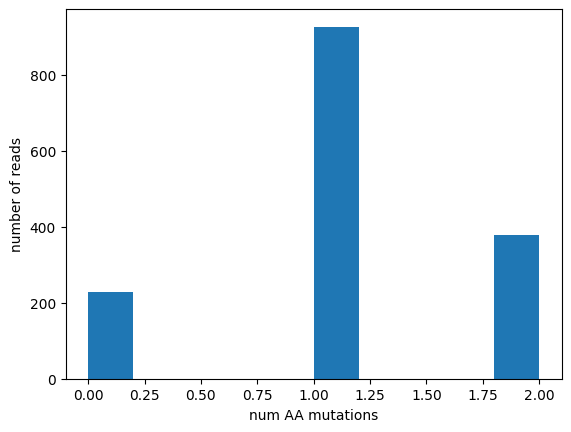

In [41]:
plt.hist(df['numaa_mut'])
plt.xlabel('num AA mutations')
plt.ylabel('number of reads')
plt.show()

In [42]:
df.shape

(1532, 18)

In [43]:
f = df['numins'] + df['numdel'] < 6
print(f'Removing {sum(~f)} ({sum(~f)/len(f)*100:0.2f}%) reads with num indel >= 6')
df = df.loc[f]

Removing 124 (8.09%) reads with num indel >= 6


In [44]:
df.shape

(1408, 18)

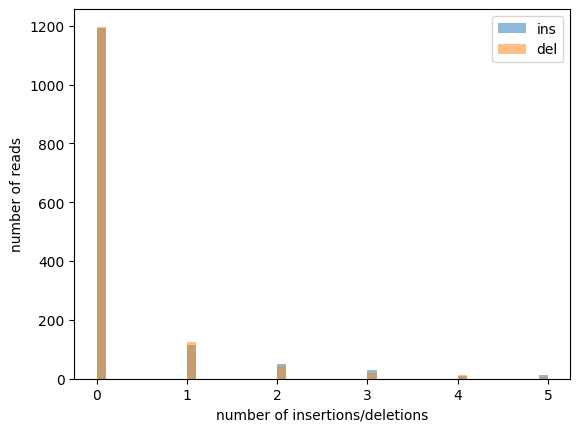

In [45]:
# look at distribution of # of indels across reads
plt.hist(df['numins'], label='ins', bins=50, alpha=0.5)
plt.hist(df['numdel'], label='del', bins=50, alpha=0.5)
plt.legend()
plt.xlabel('number of insertions/deletions')
plt.ylabel('number of reads')
plt.show()

In [46]:
# explore other reasons reads were rejected - this value represents rejected reads to main STING refgene
len(errs['STING'])

577

In [47]:
tmp = pd.Series(errs['STING']).value_counts()
tmp['kept'] = df.shape[0]
tmp = pd.DataFrame(tmp)
tmp['frac'] = tmp['count']/sum(tmp['count'])
tmp.sort_values(by='count', ascending=False)

,count,frac
kept,1408,0.709320
not_aligned,257,0.129471
too many aa mutations,132,0.066499
no 10x,122,0.061461
not enough STING coverage,55,0.027708
no gene seq,11,0.005542


In [48]:
output_dir

'output/01_output'

In [49]:
df['10xdist'].mode()

0    62
Name: 10xdist, dtype: int64

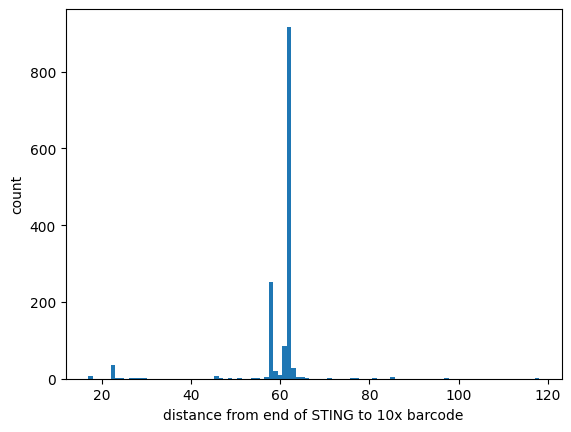

In [50]:
# We expect this distance to be 62 base pairs

plt.hist(df['10xdist'], bins=100)#, bins=np.arange(0, 200))
plt.xlabel('distance from end of STING to 10x barcode')
#plt.yscale('log')
plt.ylabel('count')
plt.show()

1347 0.9566761363636364


Text(0, 0.5, 'count')

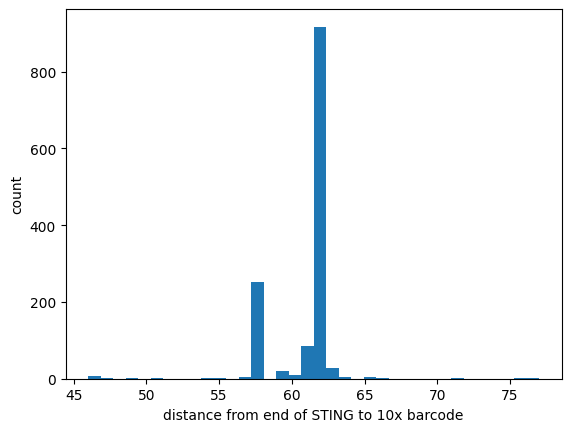

In [51]:
# This is actual distance between 10x barcode and STING. Expected length is 62
# We expect some indels (between gene end and anchorseq), but remove reads where this is way too big or small
f = (df['10xdist'] >=45) & (df['10xdist'] < 80)
print(sum(f), sum(f)/len(f))
plt.hist(df.loc[f,'10xdist'], bins=36)
plt.xlabel('distance from end of STING to 10x barcode')
plt.ylabel('count')

In [52]:
print(f'Removing {sum(~f)} ({sum(~f)/len(f)*100:0.2f}%) barcodes with 10x dist < 45 or > 80')
df = df.loc[f].copy()

Removing 61 (4.33%) barcodes with 10x dist < 45 or > 80


In [53]:
df['nummut'] = [0 if x=='mSTING_WT' else len(x.split(',')) for x in df['aa_mut']]
df['nummut'].value_counts()

nummut
1    821
2    322
0    204
Name: count, dtype: int64

In [54]:
df['nummut'].value_counts(normalize=True)

nummut
1    0.609503
2    0.239050
0    0.151448
Name: proportion, dtype: float64

In [55]:
sum(df['aa_mut'] == 'mSTING_WT')/df.shape[0]

0.1514476614699332

In [56]:
spikeIns = [x for x in variants.index if not x.endswith('X')]
spikeIns

['mSTING_WT',
 'STOP',
 'V146L',
 'N153S',
 'V154M',
 'S161A',
 'I229A',
 'Y239S',
 'N241A',
 'S365A',
 'RRAA',
 'RRDD',
 'dCTT',
 'dUPR']

In [57]:
spikeIns0 = [x for x in variants.index if not x.endswith('X') and not x[1:-1].isdigit()]
spikeIns0

['mSTING_WT', 'STOP', 'RRAA', 'RRDD', 'dCTT', 'dUPR']

In [58]:
f = df['aa_mut'].isin(spikeIns)
df.loc[f,'aa_mut'].value_counts()

aa_mut
mSTING_WT    204
STOP          82
RRAA           1
S161A          1
Name: count, dtype: int64

In [59]:
f = df['aa_mut'].isin(spikeIns0)
df.loc[f,'aa_mut'].value_counts()
print(f'Removing {sum(f)} reads that map to non-positional spike-ins')
df = df.loc[~f]

Removing 287 reads that map to non-positional spike-ins


In [60]:
df.shape

(1060, 19)

In [61]:
# save progress to file so far, in next step we will reduce to unique barcodes
outfile=f'{output_dir}/pacbio_mapped_variants_{sample_name_nospace}.txt.gz'
print(f'Writing mapped variants to {outfile}')
df.to_csv(outfile, sep='\t', compression='gzip')

Writing mapped variants to output/01_output/pacbio_mapped_variants_EO771.lmb_pacbio_run_1_example_reads.txt.gz


In [62]:
# Delete bam file when finished, can be reproduced quickly enough
for ref in ['STING']:
    aligned_file = f'{output_dir}/{ref}.bam'
    !rm -f {aligned_file}

## Reduce to unique barcode/aa mutations

In [63]:
os.getcwd()

'/data/satseq_processing/SatSeq_10x_Variant_Calling'

In [64]:
output_dir

'output/01_output'

In [65]:
# If you are starting here, change this to True and load data with this command
if False:
    df = pd.read_csv(f'{output_dir}/pacbio_mapped_variants.txt.gz', sep='\t', index_col=0)
df.shape

(1060, 19)

__Compute entropy of each barcode using all unique AA muts__

In [66]:
# Create a dataframe with each unique mutation - split double-mutations into two entries with count=0.5 each, single mutations get count=1
df2 = df[['bc', 'aa_mut']].copy()
df3 = df.loc[df['numaa_mut'] == 2, ['bc', 'aa_mut']].copy()
df2['count'] = [0.5 if ',' in x else 1.0 for x in df2['aa_mut']]
df3['count'] = 0.5
df2['aa_mut'] = [x.split(',')[0] for x in df2['aa_mut']]
df3['aa_mut'] = [x.split(',')[1] for x in df3['aa_mut']]
dfent = pd.concat([df2,df3], axis=0)
del([df2, df3])
dfent

,bc,aa_mut,count
6,TTACATCATGAATAGGCGCTTATCCTCCCAGCTACT,A97V,1.0
9,GAGTGATGATTTTTTCCGCTCTTAGATGCAGGCACC,P316Y,1.0
10,TGCACGAGTCTAGTGGCGCTACCATATGAGGACTCC,S53M,1.0
13,TGAAAACATGTTGGCACGCTATTGTACTGGCGTTGC,P202L,1.0
15,TAGTGATTATGCATTTCGCTCGTACCTGATCCCTAC,K275V,1.0
...,...,...,...
1505,GCGAGTGGATTGACGGCGCTGGCCATACTATCTATC,E69K,0.5
1511,ACTGTTAGGTCTCAAGCGCTGACGTCAGGAGTAATG,P372A,0.5
1523,GAAGAGCTCTTGGCTGCGCTTAGTGCCGCGAACAAG,D113Y,0.5
1524,AGTCCTGGAAAATGTTCGCTGAGATGCCATGCTAAC,G165R,0.5


In [67]:
bc_mut_df = dfent.groupby(['bc', 'aa_mut']).sum()
bc_mut_df

count
bc                                   aa_mut       
AAAAGAGCTGTTCGTGCGCTCAAAGGCCACAGTAAA L60A      1.0
AAAAGCGGAAGAGGATAGAACGAGGAATTAGCAACG L184C     1.0
AAAATCGAAAGTTTCCCGCTCCAGCGGTAGGTAGTA A52T      1.0
AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT A261V     0.5
                                     L63Y      0.5
...                                            ...
TTTTTCCTGGTAAGGCCGCTCAAAGTACATGCTCAC L324V     1.0
TTTTTCTAGAATGTACCGCTAGCCTCCACACCGATA L211C     1.0
TTTTTCTTCTTGTACTCGCTCCGTACTGTTTCACAC A112V     0.5
                                     Y3Q       0.5
TTTTTTATTGAAGCCTCGCTGATCGATTAGCCAGGC D113N     1.0

[1348 rows x 1 columns]

In [68]:
bc_mut_df = bc_mut_df.reset_index().set_index('bc').merge(dfent[['bc', 'count']].groupby('bc').sum(), left_index=True, right_index=True,
                                                suffixes=('', '_bc')).reset_index()
bc_mut_df['frac'] = bc_mut_df['count']/bc_mut_df['count_bc']
bc_mut_df['entropy_single'] = -bc_mut_df['frac']*np.log(bc_mut_df['frac'])
bc_df = bc_mut_df[['entropy_single', 'bc']].groupby('bc').sum().merge(dfent[['bc', 'count']].groupby('bc').sum(), 
                                                                      left_index=True, right_index=True).rename(columns={'entropy_single':'entropy'})

bc_df['entropy'] = bc_df['entropy']/np.log(2.0*bc_df['count'])

In [69]:
bc_mut_df

,bc,aa_mut,count,count_bc,frac,entropy_single
0,AAAAGAGCTGTTCGTGCGCTCAAAGGCCACAGTAAA,L60A,1.0,1.0,1.0,-0.000000
1,AAAAGCGGAAGAGGATAGAACGAGGAATTAGCAACG,L184C,1.0,1.0,1.0,-0.000000
2,AAAATCGAAAGTTTCCCGCTCCAGCGGTAGGTAGTA,A52T,1.0,1.0,1.0,-0.000000
3,AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,A261V,0.5,1.0,0.5,0.346574
4,AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,L63Y,0.5,1.0,0.5,0.346574
...,...,...,...,...,...,...
1343,TTTTTCCTGGTAAGGCCGCTCAAAGTACATGCTCAC,L324V,1.0,1.0,1.0,-0.000000
1344,TTTTTCTAGAATGTACCGCTAGCCTCCACACCGATA,L211C,1.0,1.0,1.0,-0.000000
1345,TTTTTCTTCTTGTACTCGCTCCGTACTGTTTCACAC,A112V,0.5,1.0,0.5,0.346574
1346,TTTTTCTTCTTGTACTCGCTCCGTACTGTTTCACAC,Y3Q,0.5,1.0,0.5,0.346574


In [70]:
bc_df

,entropy,count
bc,,
AAAAGAGCTGTTCGTGCGCTCAAAGGCCACAGTAAA,0.0,1.0
AAAAGCGGAAGAGGATAGAACGAGGAATTAGCAACG,0.0,1.0
AAAATCGAAAGTTTCCCGCTCCAGCGGTAGGTAGTA,0.0,1.0
AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,1.0,1.0
AAACAGTAATACCGGGCGCTTTACGCATAGCTTCGC,0.0,1.0
...,...,...
TTTTTATTTGGTTCTACGCTGCTAACCAACTACCTC,0.0,1.0
TTTTTCCTGGTAAGGCCGCTCAAAGTACATGCTCAC,0.0,1.0
TTTTTCTAGAATGTACCGCTAGCCTCCACACCGATA,0.0,1.0


In [71]:
def get_nearest_variant(origbc):
    varbc=origbc[20:]
    f = varbc == variants['sequence']
    if sum(f) == 1:
        var=variants.loc[f].index[0]
        d=0
    else:
        ds = [editdistance.eval(varbc,x) for x in variants['sequence']]
        tmp = pd.DataFrame({'variant':variants.index, 'd':ds}).sort_values(by='d')
        var =tmp.iloc[0]['variant']
        d = tmp.iloc[0]['d']
    return (origbc, varbc, var, d)

In [72]:
p = multiprocessing.Pool(40)

chunkSize=10000
print('calling get_nearest_variant on all barcodes')
result = p.map_async(get_nearest_variant, bc_df.index, chunkSize)
p.close()
print('done')

calling get_nearest_variant on all barcodes
done


In [73]:
vardist = pd.DataFrame(result.get(), columns=["bc", "var_bc", "closest_variant", "vardist"]).set_index("bc")
bc_df['closest_variant'] = vardist['closest_variant']
bc_df['vardist'] = vardist['vardist']

In [74]:
f = bc_df['closest_variant'].isin(spikeIns0)
print(f'Removing {sum(f)} barcodes whose closest TWIST sequence is a non-positional spike-in')
bc_df = bc_df.loc[~f].copy()
print(bc_df.shape[0])

Removing 9 barcodes whose closest TWIST sequence is a non-positional spike-in
990


In [75]:
bc_df['closest_variant_pos'] = [int(x[1:-1]) for x in bc_df['closest_variant']].copy()

In [76]:
bc_df

,entropy,count,closest_variant,vardist,closest_variant_pos
bc,,,,,
AAAAGAGCTGTTCGTGCGCTCAAAGGCCACAGTAAA,0.0,1.0,A112X,0,112
AAAATCGAAAGTTTCCCGCTCCAGCGGTAGGTAGTA,0.0,1.0,A52X,0,52
AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,1.0,1.0,L63X,0,63
AAACAGTAATACCGGGCGCTTTACGCATAGCTTCGC,0.0,1.0,M96X,0,96
AAAGCACGTTTGGATGCGCTCCTCTACTTCCGTATT,0.0,1.0,N343X,0,343
...,...,...,...,...,...
TTTTTATTTGGTTCTACGCTGCTAACCAACTACCTC,0.0,1.0,R374X,0,374
TTTTTCCTGGTAAGGCCGCTCAAAGTACATGCTCAC,0.0,1.0,Q227X,0,227
TTTTTCTAGAATGTACCGCTAGCCTCCACACCGATA,0.0,1.0,V27X,0,27


In [77]:
# Doing the inner merge will drop rows from bc_mut_df that correspond to non-positional spike-in barcodes
bc_mut_df = bc_mut_df.merge(bc_df.drop(columns='count'), left_on='bc', right_index=True, how='inner')

In [78]:
bc_mut_df

,bc,aa_mut,count,count_bc,frac,entropy_single,entropy,closest_variant,vardist,closest_variant_pos
0,AAAAGAGCTGTTCGTGCGCTCAAAGGCCACAGTAAA,L60A,1.0,1.0,1.0,-0.000000,0.0,A112X,0,112
2,AAAATCGAAAGTTTCCCGCTCCAGCGGTAGGTAGTA,A52T,1.0,1.0,1.0,-0.000000,0.0,A52X,0,52
3,AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,A261V,0.5,1.0,0.5,0.346574,1.0,L63X,0,63
4,AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,L63Y,0.5,1.0,0.5,0.346574,1.0,L63X,0,63
5,AAACAGTAATACCGGGCGCTTTACGCATAGCTTCGC,M96K,1.0,1.0,1.0,-0.000000,0.0,M96X,0,96
...,...,...,...,...,...,...,...,...,...,...
1343,TTTTTCCTGGTAAGGCCGCTCAAAGTACATGCTCAC,L324V,1.0,1.0,1.0,-0.000000,0.0,Q227X,0,227
1344,TTTTTCTAGAATGTACCGCTAGCCTCCACACCGATA,L211C,1.0,1.0,1.0,-0.000000,0.0,V27X,0,27
1345,TTTTTCTTCTTGTACTCGCTCCGTACTGTTTCACAC,A112V,0.5,1.0,0.5,0.346574,1.0,Y3X,0,3
1346,TTTTTCTTCTTGTACTCGCTCCGTACTGTTTCACAC,Y3Q,0.5,1.0,0.5,0.346574,1.0,Y3X,0,3


(array([948.,  12.,   0.,  11.,   0.,   0.,   2.,   0.,  15.,   2.]),
 array([0. , 0.6, 1.2, 1.8, 2.4, 3. , 3.6, 4.2, 4.8, 5.4, 6. ]),
 <BarContainer object of 10 artists>)

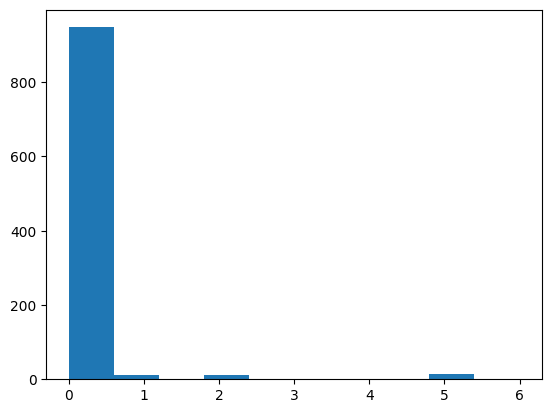

In [79]:
plt.hist(bc_df['vardist'])

In [80]:
bc_mut_df['aa_mut_pos'] = [int(x[1:-1]) for x in bc_mut_df['aa_mut']]

In [81]:
bc_mut_df['match_pos'] = bc_mut_df['closest_variant_pos'] == bc_mut_df['aa_mut_pos']
np.mean(bc_mut_df['match_pos'])

0.43530291697830964

In [82]:
bc_mut_df['match_pos'].value_counts(dropna=False)

match_pos
False    755
True     582
Name: count, dtype: int64

In [83]:
# set aa_mut to the most frequently observed per barcode - but prefer mutations in the expected position
# still need to choose entropy cutoff to see whether we will keep this bc/aa_mut pairing
tmp = bc_mut_df.sort_values(by=['bc', 'match_pos', 'frac','aa_mut'], ascending=(True, False, False, True))
tmp = tmp.loc[~tmp['bc'].duplicated()].set_index('bc')
bc_df['aa_mut'] = tmp['aa_mut']
bc_df['aa_mut_frac'] = tmp['count']/tmp['count_bc']
bc_df['match_pos'] = tmp['match_pos'].astype(bool)

In [84]:
bc_df

,entropy,count,closest_variant,vardist,closest_variant_pos,aa_mut,aa_mut_frac,match_pos
bc,,,,,,,,
AAAAGAGCTGTTCGTGCGCTCAAAGGCCACAGTAAA,0.0,1.0,A112X,0,112,L60A,1.0,False
AAAATCGAAAGTTTCCCGCTCCAGCGGTAGGTAGTA,0.0,1.0,A52X,0,52,A52T,1.0,True
AAAATGTCCCGTGGACCGCTCTCAGAGTGCTACTAT,1.0,1.0,L63X,0,63,L63Y,0.5,True
AAACAGTAATACCGGGCGCTTTACGCATAGCTTCGC,0.0,1.0,M96X,0,96,M96K,1.0,True
AAAGCACGTTTGGATGCGCTCCTCTACTTCCGTATT,0.0,1.0,N343X,0,343,N343K,1.0,True
...,...,...,...,...,...,...,...,...
TTTTTATTTGGTTCTACGCTGCTAACCAACTACCTC,0.0,1.0,R374X,0,374,R374N,1.0,True
TTTTTCCTGGTAAGGCCGCTCAAAGTACATGCTCAC,0.0,1.0,Q227X,0,227,L324V,1.0,False
TTTTTCTAGAATGTACCGCTAGCCTCCACACCGATA,0.0,1.0,V27X,0,27,L211C,1.0,False


In [85]:
bc_df['match_pos'].value_counts()

match_pos
True     571
False    419
Name: count, dtype: int64

In [86]:
bc_df['match_pos'].value_counts(normalize=True)

match_pos
True     0.576768
False    0.423232
Name: proportion, dtype: float64

In [87]:
# mark which ones have a tie... are they always high entropy?
#  - just change sort parameter, the only sort column that changes is aa_mut. So if only one aa_mut is best it will still be on top
#  - if a different one comes out it is a tie
tmp = bc_mut_df.sort_values(by=['bc', 'match_pos', 'frac', 'aa_mut'], ascending=(True, False, False, False))
tmp = tmp.loc[~tmp['bc'].duplicated()].set_index('bc')
bc_df['aa_mut_tied'] = tmp['aa_mut'] != bc_df['aa_mut']

In [88]:
np.mean(bc_df['match_pos'])

0.5767676767676768

In [89]:
sum(bc_df['aa_mut_tied'])

110

In [90]:
sum(bc_df['aa_mut_tied'])/bc_df.shape[0]

0.1111111111111111

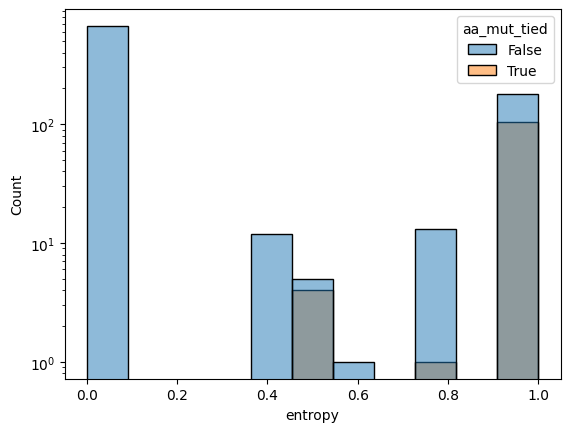

In [91]:
sns.histplot(data=bc_df, x='entropy', hue='aa_mut_tied')
plt.yscale('log')

In [92]:
# If there is a tie and it matches twist position, use it as a positional mutation
# Note: It does not count as a tie if two AA muts are equally frequent but one matches TWIST and the other doesn't. Because
#  ranking considers TWIST match as first criteria. Therefore if match_pos and aa_mut_tied, then both variants must have match_pos
f = (bc_df['aa_mut_tied']) & (bc_df['match_pos'])
print(f'{sum(f)} barcodes have tie for different mutations at expected position, changing to positional mutation')
bc_df.loc[f,'aa_mut'] = [x[:-1]+'X' for x in bc_df.loc[f,'aa_mut']]
bc_df.loc[f,'aa_mut_tied'] = False
bc_df.loc[f]

5 barcodes have tie for different mutations at expected position, changing to positional mutation


,entropy,count,closest_variant,vardist,closest_variant_pos,aa_mut,aa_mut_frac,match_pos,aa_mut_tied
bc,,,,,,,,,
TAAGTCACTGGTCTCGCGCTAGCCTCCACACCGATA,0.75,4.0,V27X,0,27,V27X,0.25,True,False
TAAGTCACTGGTCTCGCGCTCAAACCGCATCCACCT,0.50,2.0,A22X,0,22,A22X,0.50,True,False
TAAGTCACTGGTCTCGCGCTGGATCTAGTGCAAGTA,0.50,2.0,G90X,0,90,G90X,0.50,True,False
TAAGTCACTGGTCTCGCGCTTGCGAAACAGTGAGAG,1.00,2.0,T262X,0,262,T262X,0.25,True,False
TAAGTCACTGGTCTCGCGCTTGTCCTATTTCGCGCT,1.00,2.0,E359X,0,359,E359X,0.25,True,False


Deleting 105 (10.61%) barcodes with tie for best mutation, none matching TWIST


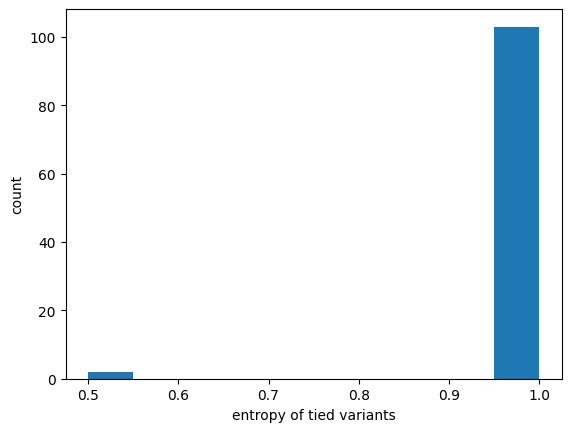

In [93]:
# otherwise if there is a tie, delete
f = bc_df['aa_mut_tied']
print(f'Deleting {sum(f)} ({sum(f)/len(f)*100:0.2f}%) barcodes with tie for best mutation, none matching TWIST')
plt.hist(bc_df.loc[f,'entropy'])
plt.xlabel('entropy of tied variants')
plt.ylabel('count')
bc_df = bc_df.loc[~f]

In [94]:
bc_df.shape

(885, 9)

Text(0, 0.5, 'count')

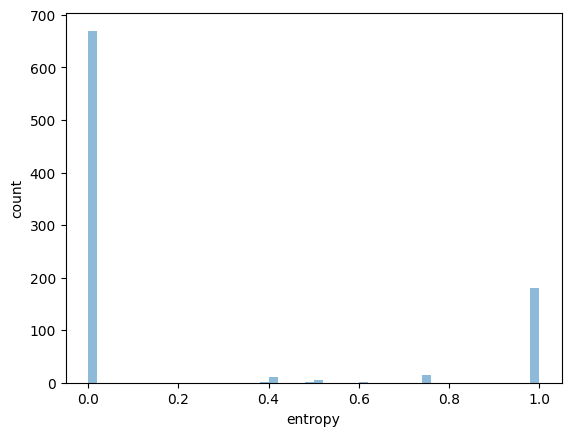

In [95]:
plt.hist(bc_df['entropy'], bins=50, label='all', alpha=0.5)
plt.xlabel('entropy')
plt.ylabel('count')

Text(0, 0.5, 'count')

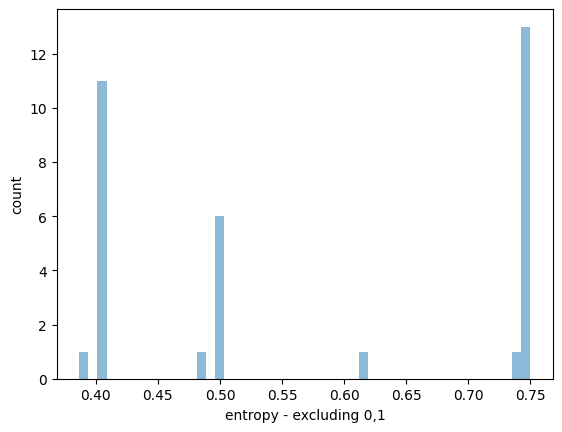

In [96]:
f = (bc_df['entropy'] > 0) & (bc_df['entropy'] < 1)
h = plt.hist(bc_df.loc[f,'entropy'], bins=50, label='all', alpha=0.5)
plt.xlabel('entropy - excluding 0,1')
plt.ylabel('count')

Text(0, 0.5, 'count')

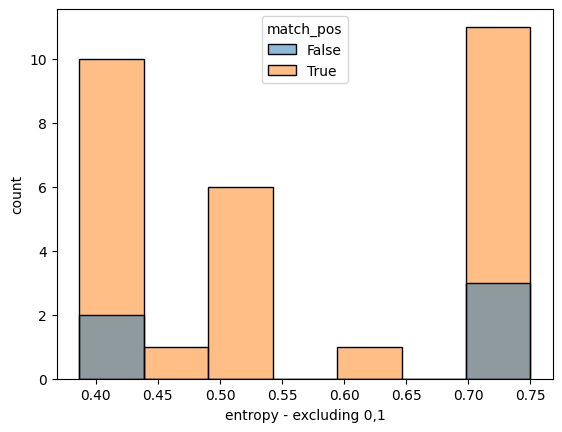

In [97]:
f = (bc_df['entropy'] > 0) & (bc_df['entropy'] < 1)
sns.histplot(data=bc_df.loc[f], x='entropy', hue='match_pos')
plt.xlabel('entropy - excluding 0,1')
plt.ylabel('count')

In [98]:
bc_df['match_pos'].value_counts(dropna=False)

match_pos
True     571
False    314
Name: count, dtype: int64

In [99]:
bc_df['match_pos'].value_counts(dropna=False, normalize=True)

match_pos
True     0.645198
False    0.354802
Name: proportion, dtype: float64

In [100]:
f  = (bc_df['entropy'] > 0.5) & (~(bc_df['match_pos'].astype(bool)))
print(f'Deleting {sum(f)} ({sum(f)/len(f)*100:0.2f}%) barcodes with entropy > 0.5 and and not matching TWIST')
bc_df = bc_df.loc[~f].copy()

Deleting 3 (0.34%) barcodes with entropy > 0.5 and and not matching TWIST


In [101]:
bc_df['score'] = (1.0-bc_df['entropy'])*np.log10(bc_df['aa_mut_frac']*bc_df['count'])

Text(0, 0.5, '# of barcodes')

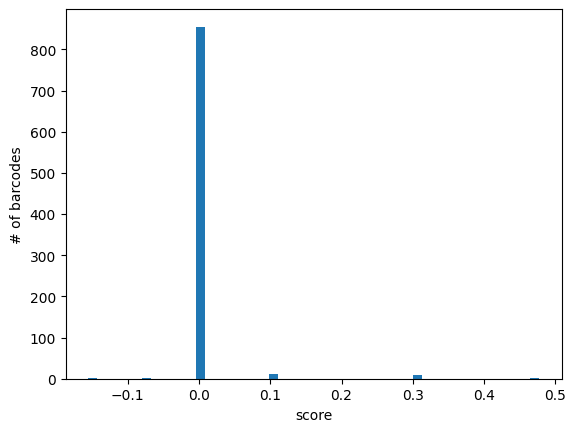

In [102]:
plt.hist(bc_df['score'], bins=50)
plt.xlabel('score')
plt.ylabel('# of barcodes')

In [103]:
bc_df.columns

Index(['entropy', 'count', 'closest_variant', 'vardist', 'closest_variant_pos',
       'aa_mut', 'aa_mut_frac', 'match_pos', 'aa_mut_tied', 'score'],
      dtype='object')

In [104]:
bc_df['closest_variant_pos'] = [int(x[1:-1]) for x in bc_df['closest_variant']]

Text(0.5, 1.0, 'EO771.lmb pacbio run 1 example reads')

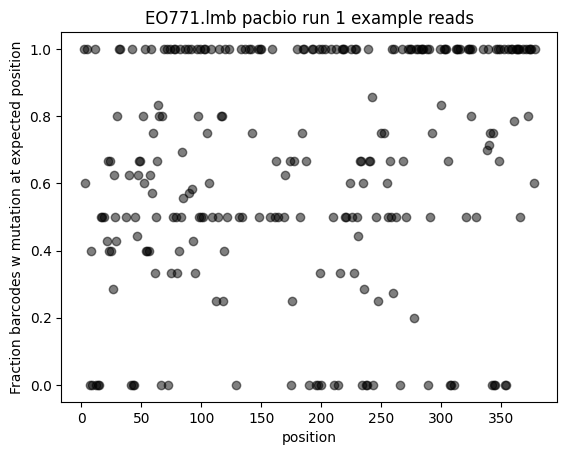

In [105]:
tmp = bc_df[['closest_variant_pos', 'match_pos']].groupby('closest_variant_pos').mean()
tmp.to_csv(f'{output_dir}/recomb_plot_data.txt', sep='\t')
plt.scatter(tmp.index, tmp['match_pos'], color='black', alpha=0.5)
plt.ylim(-0.05, 1.05)
plt.xlabel('position')
plt.ylabel('Fraction barcodes w mutation at expected position')
plt.title(sample_name)

In [106]:
bcmap = bc_df[['aa_mut', 'score', 'closest_variant', 'vardist', 'match_pos', 'count', 'closest_variant_pos']].copy()

__Write barcode map, this is used in 10x mapping__

In [107]:
bcmap.to_csv(f'{output_dir}/bcmap_{sample_name_nospace}.txt.gz', sep='\t')
print(f'Wrote {output_dir}/bcmap_{sample_name_nospace}.txt.gz')

Wrote output/01_output/bcmap_EO771.lmb_pacbio_run_1_example_reads.txt.gz


In [108]:
output_dir

'output/01_output'

### Plot of position vs AA mutation coverage

In [109]:
# get matrix wt_matrix indicating WT alleles in STING
tmp = variants[['pos','wt_aa']].rename(columns={'wt_aa':'newaa'}).copy()
tmp = tmp.loc[tmp['pos'] > 0]
tmp = tmp.reset_index(drop=True)
tmp = tmp[~tmp.duplicated()].sort_values(by='pos').set_index('pos', drop=True)
tmp['val'] = 1.0
wt_mat = tmp.reset_index().pivot(columns='newaa', index='pos')
wt_mat[pd.isna(wt_mat)] = 0.0
wt_mat.columns=[x[1] for x in wt_mat.columns]

In [110]:
wt_mat

,A,C,D,E,F,G,H,I,K,L,M,N,P,Q,R,S,T,V,W,Y
pos,,,,,,,,,,,,,,,,,,,,
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
374,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0
375,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
376,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [111]:
np.sum(wt_mat==1, axis=1).sort_values()

pos
345    1
346    1
347    1
348    1
349    1
      ..
375    1
376    1
377    1
378    1
1      1
Length: 378, dtype: int64

In [112]:
# Same as plot_coverage but with new colors requested by matt:
# (Red = Not detected, Black = Native, Green = Detected)
# Only implemeneted for the observed_per_pos plot (binary yes/no observed)

# If show_counts is True, then use gradient colormap to show number of reads, WT will be pink
# If show_counts is False, blue=count > 0 , red=count=0, black=WT
def plot_coverage(bcmap, bcmap_name, output_dir, show_counts=True, show=True):
    f =  (~(bcmap['aa_mut'].isin(['STOP', 'RRAA', 'dUPR', 'RRDD', 'dCTT', 'mSTING_WT'])))
    bcmap['pos'] = [int(x[1:-1]) for x in bcmap['aa_mut']]
    f = (f) & (bcmap['pos'] <= 378) 
    bcmap['newaa'] = ''
    bcmap.loc[f,'newaa'] = [x[-1] for x in bcmap.loc[f,'aa_mut']]
    f = (f) & (bcmap['newaa'] != '_')
    colorder = ['A', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'K', 'L', 'M', 'N', 'P', 'Q',
       'R', 'S', 'T', 'V', 'W', 'Y']#, '_']
    positions = list(np.arange(1,379))
    tmp = bcmap.loc[bcmap['newaa'] != '', ['pos', 'newaa']].copy()
    tmp['pos'] = pd.Categorical(tmp['pos'], categories=positions)
    tmp['newaa'] = pd.Categorical(tmp['newaa'], categories=colorder)
    tmp = tmp.value_counts().reset_index()
    bc_count_mat = tmp.pivot_table(columns='newaa', index='pos', values='count', observed=False, dropna=False).loc[positions, colorder]
    f = pd.isna(bc_count_mat)
    bc_count_mat[f]=0
    if np.sum(np.sum(bc_count_mat*wt_mat, axis=1))!=0:
        print('error')

    

    _, ax = plt.subplots(figsize=(6, 20))
    if show_counts:
        label='counts'
        wt_color='rosybrown'
        sns.heatmap(bc_count_mat > 0, ax=ax, cmap='Blues',cbar=True)
    else:
        cmap = ListedColormap(["red", "skyblue"])
        label='observed'
        wt_color='black'
        sns.heatmap(bc_count_mat > 0, ax=ax, cmap=cmap,cbar=False, vmin=0.0, vmax=1)
    numfound = np.sum(np.sum(bc_count_mat > 0, axis=1))
    fracfound = numfound/np.sum(np.sum(wt_mat!=1, axis=1))
    print(f'{bcmap_name}\t{numfound}\t{fracfound*100:0.2f}%')
    for i in wt_mat.index:
        position = np.where(wt_mat[colorder].loc[i] != 0)[0][0]
        ax.add_patch(Rectangle((position, i-1), 1, 1, fill=True, edgecolor=wt_color, lw=0, facecolor=wt_color))

    plt.title(f'{bcmap_name} AA muts {label}')
    
    plt.savefig(f'{output_dir}/{label}_per_pos_aa_{bcmap_name}.png', dpi=300, bbox_inches='tight')
    plt.savefig(f'{output_dir}/{label}_per_pos_aa_{bcmap_name}.svg', bbox_inches='tight')
    if show:
        plt.show()
    else:
        plt.clf()

EO771.lmb pacbio run 1 example reads	775	10.79%


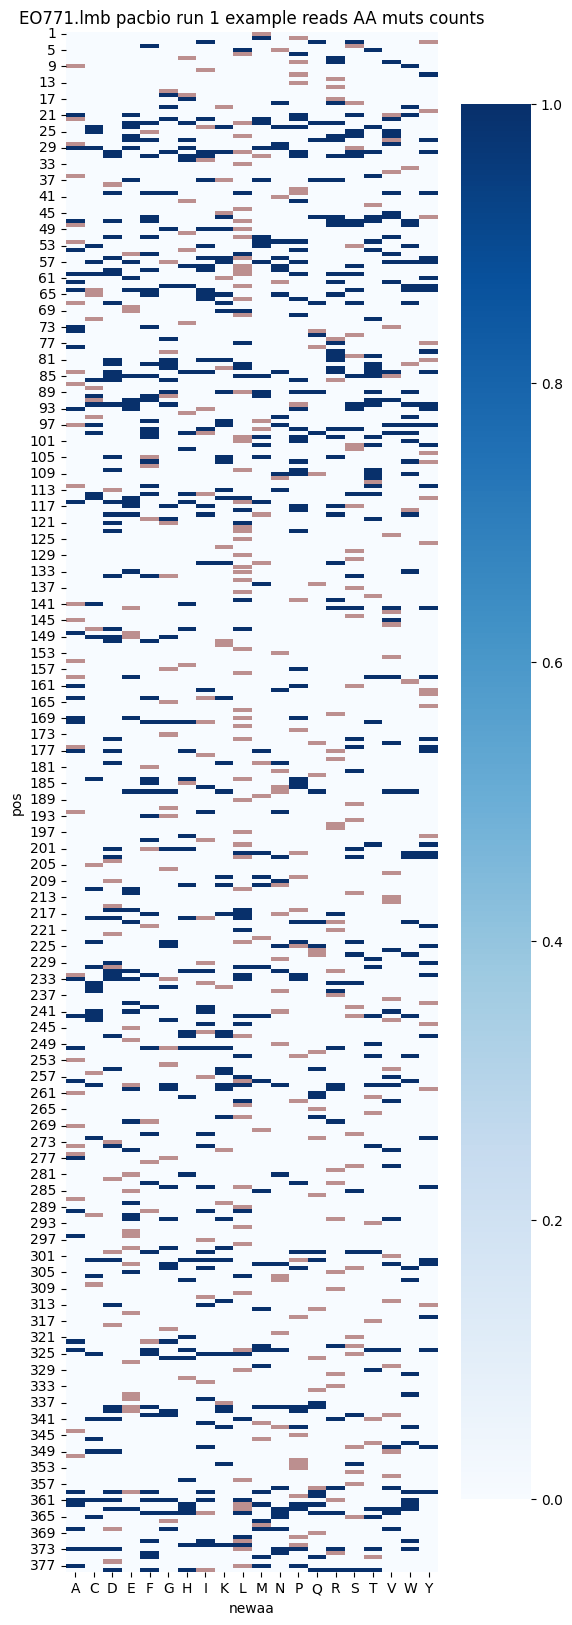

In [113]:
plot_coverage(bcmap, sample_name, output_dir)

EO771.lmb pacbio run 1 example reads	775	10.79%


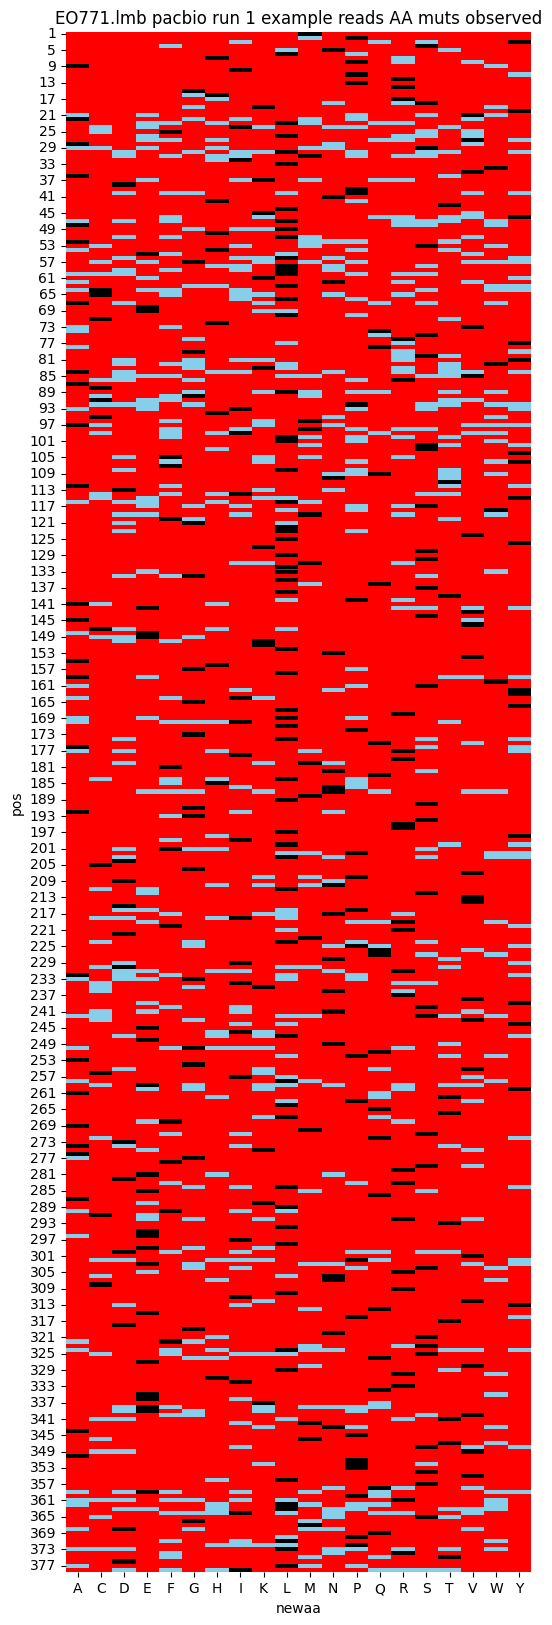

In [114]:
# blue = observed
# red = not observed
# black = WT
plot_coverage(bcmap, sample_name, output_dir, show_counts=False)